<a href="https://colab.research.google.com/github/PratikAmane05/ACV_Case_Study/blob/main/ACV_CA2_Case_Study_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install -q opencv-contrib-python matplotlib numpy


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)

if hasattr(cv2, "SIFT_create"):
    print("SIFT is available!")
else:
    print("SIFT is not available. Check OpenCV installation.")


OpenCV Version: 4.14.0
SIFT is available!


Reference image downloaded successfully!
Image dimensions: (597, 455, 3)


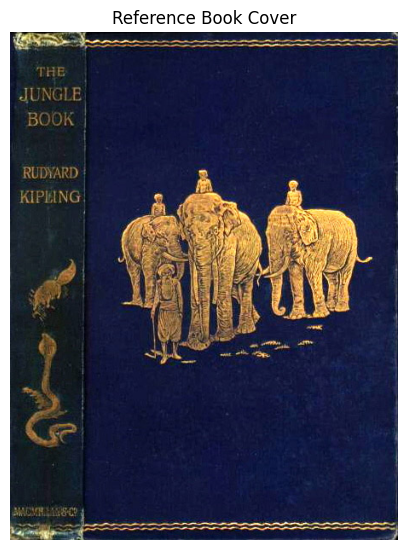

In [ ]:

import requests
import cv2
import matplotlib.pyplot as plt

# Get the direct image URL from Wikimedia
api_url = "https://commons.wikimedia.org/w/api.php"

params = {
    "action": "query",
    "titles": "File:JunglebookCover.jpg",
    "prop": "imageinfo",
    "iiprop": "url",
    "format": "json"
}

headers = {"User-Agent": "ACVStudentAssignment/1.0"}

response = requests.get(
    api_url, params=params, headers=headers, timeout=30
)
response.raise_for_status()

data = response.json()
page = next(iter(data["query"]["pages"].values()))
image_url = page["imageinfo"][0]["url"]

# Download the image
image_response = requests.get(
    image_url, headers=headers, timeout=30
)
image_response.raise_for_status()

with open("reference_book.jpg", "wb") as f:
    f.write(image_response.content)

# Read and display
reference = cv2.imread("reference_book.jpg")

if reference is None:
    raise ValueError("Image could not be opened.")

reference = cv2.cvtColor(reference, cv2.COLOR_BGR2RGB)

print("Reference image downloaded successfully!")
print("Image dimensions:", reference.shape)

plt.figure(figsize=(5, 7))
plt.imshow(reference)
plt.title("Reference Book Cover")
plt.axis("off")
plt.show()


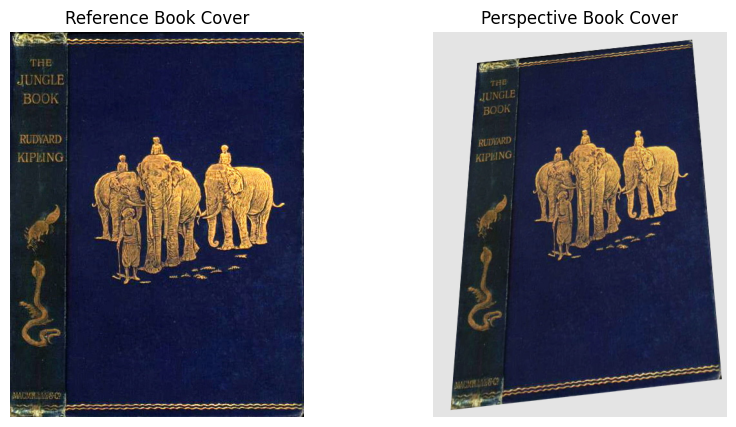

Query image created successfully!


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Get image dimensions
h, w = reference.shape[:2]

# Original four corners
src_points = np.float32([
    [0, 0],
    [w-1, 0],
    [w-1, h-1],
    [0, h-1]
])

# New corners to create a perspective effect
dst_points = np.float32([
    [0.15*w, 0.08*h],
    [0.88*w, 0.02*h],
    [0.98*w, 0.90*h],
    [0.06*w, 0.98*h]
])

# Apply perspective transformation
matrix = cv2.getPerspectiveTransform(src_points, dst_points)

query = cv2.warpPerspective(
    reference,
    matrix,
    (w, h),
    borderValue=(245, 245, 245)
)

# Slight brightness adjustment
query = cv2.convertScaleAbs(query, alpha=0.9, beta=8)

# Display both images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(reference)
plt.title("Reference Book Cover")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(query)
plt.title("Perspective Book Cover")
plt.axis("off")

plt.show()

# Save transformed image
cv2.imwrite(
    "query_book.jpg",
    cv2.cvtColor(query, cv2.COLOR_RGB2BGR)
)

print("Query image created successfully!")


Reference image keypoints: 1366
Query image keypoints: 1116


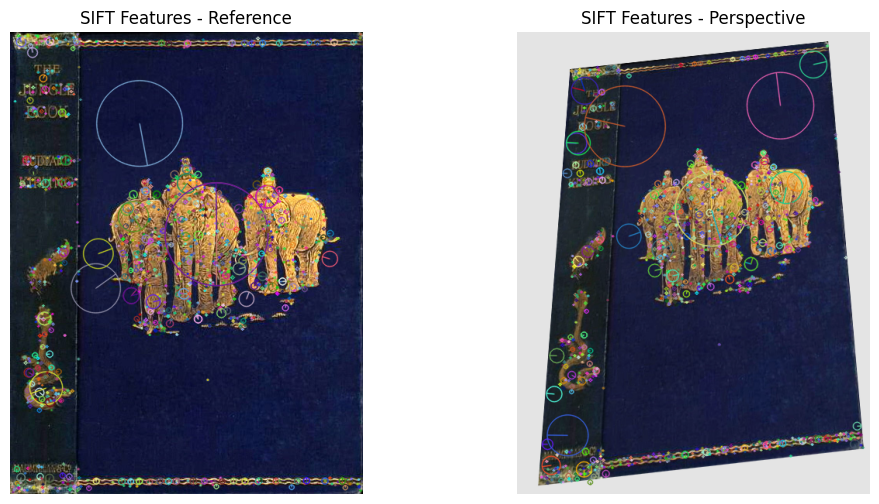

In [ ]:

# Convert both images into grayscale
ref_gray = cv2.cvtColor(reference, cv2.COLOR_RGB2GRAY)
query_gray = cv2.cvtColor(query, cv2.COLOR_RGB2GRAY)

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and calculate descriptors
kp1, des1 = sift.detectAndCompute(ref_gray, None)
kp2, des2 = sift.detectAndCompute(query_gray, None)

# Display number of detected features
print("Reference image keypoints:", len(kp1))
print("Query image keypoints:", len(kp2))

# Draw keypoints on both images
ref_features = cv2.drawKeypoints(
    reference, kp1, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

query_features = cv2.drawKeypoints(
    query, kp2, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display results
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(ref_features)
plt.title("SIFT Features - Reference")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(query_features)
plt.title("SIFT Features - Perspective")
plt.axis("off")

plt.show()


Total KNN matches: 1366
Good matches after ratio test: 553


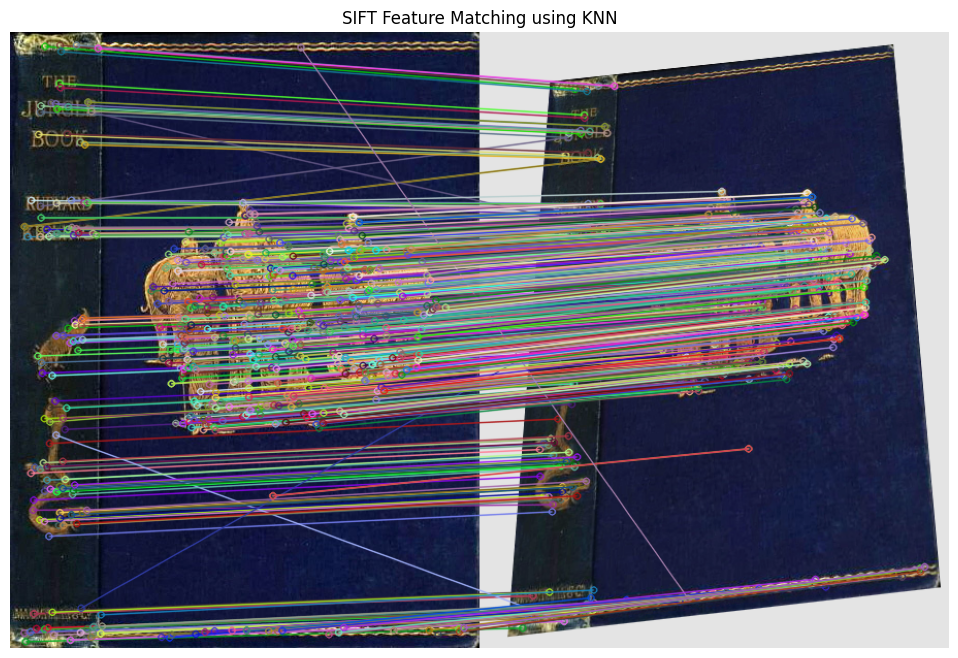

In [ ]:

# Check whether SIFT descriptors are available
if des1 is None or des2 is None:
    raise ValueError("SIFT descriptors were not detected.")

# Create Brute Force Matcher
bf = cv2.BFMatcher(cv2.NORM_L2)

# Find 2 nearest matches for each descriptor
matches = bf.knnMatch(des1, des2, k=2)

# Apply Lowe's Ratio Test
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

# Display matching results
print("Total KNN matches:", len(matches))
print("Good matches after ratio test:", len(good_matches))

# Draw matched features
matched_image = cv2.drawMatches(
    reference, kp1,
    query, kp2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(matched_image)
plt.title("SIFT Feature Matching using KNN")
plt.axis("off")
plt.show()


Good matches: 553
Correct matches (RANSAC inliers): 527
Incorrect matches (outliers): 26
Inlier percentage: 95.3 %


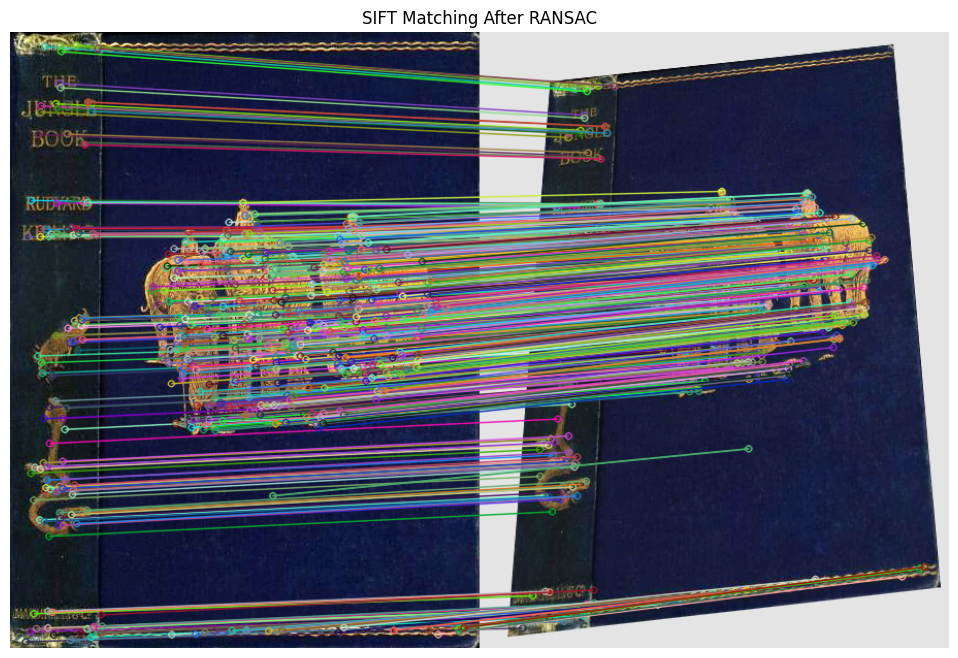

In [ ]:

# Extract coordinates of matched keypoints
src_pts = np.float32(
    [kp1[m.queryIdx].pt for m in good_matches]
).reshape(-1, 1, 2)

dst_pts = np.float32(
    [kp2[m.trainIdx].pt for m in good_matches]
).reshape(-1, 1, 2)

# Apply RANSAC
H, mask = cv2.findHomography(
    src_pts,
    dst_pts,
    cv2.RANSAC,
    5.0
)

if mask is None:
    raise ValueError("RANSAC could not estimate a valid transformation.")

# Separate correct matches
inlier_matches = [
    m for m, keep in zip(good_matches, mask.ravel())
    if keep
]

total_good = len(good_matches)
total_inliers = len(inlier_matches)

inlier_percentage = (total_inliers / total_good) * 100

print("Good matches:", total_good)
print("Correct matches (RANSAC inliers):", total_inliers)
print("Incorrect matches (outliers):", total_good - total_inliers)
print("Inlier percentage:", round(inlier_percentage, 2), "%")

# Display only geometrically consistent matches
result = cv2.drawMatches(
    reference, kp1,
    query, kp2,
    inlier_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(result)
plt.title("SIFT Matching After RANSAC")
plt.axis("off")
plt.show()


In [ ]:

import pandas as pd

results = {
    "Metric": [
        "Total KNN Matches",
        "Good Matches (Ratio Test)",
        "RANSAC Inliers",
        "RANSAC Outliers",
        "Inlier Percentage"
    ],
    "Result": [
        len(matches),
        len(good_matches),
        total_inliers,
        total_good - total_inliers,
        f"{inlier_percentage:.2f}%"
    ]
}

df = pd.DataFrame(results)
display(df)

print("\nCONCLUSION:")
print("SIFT successfully identified matching features")
print("between the original and perspective book covers.")
print(f"{total_inliers} geometrically consistent matches")
print(f"were identified with an inlier percentage of {inlier_percentage:.2f}%.")


,Metric,Result
0,Total KNN Matches,1366
1,Good Matches (Ratio Test),553
2,RANSAC Inliers,527
3,RANSAC Outliers,26
4,Inlier Percentage,95.30%



CONCLUSION:
SIFT successfully identified matching features
between the original and perspective book covers.
527 geometrically consistent matches
were identified with an inlier percentage of 95.30%.
